# Group 4: Prompted LLM (Qwen2.5-1.5B-Instruct) on MRPC

**Owner:** Tim McGowan (Group 4 is shared by the team)

Qwen is **not trained** on MRPC. We just ask it, for each pair, *"Do these two sentences mean the same thing?"*

- **Zero-shot:** the question alone.
- **Few-shot:** the question after 4 worked examples taken from the training set (2 "yes", 2 "no"), picked with each shared seed (42, 43, 44).

**How we get a probability, not just yes/no:** we look at how strongly Qwen wants to answer **"yes"** vs **"no"** as its next word, and turn those two scores into a probability with **softmax**, the same idea as DistilBERT's two scores. That gives the shared `prob_paraphrase` column, so Qwen can be compared with and combined with the other models.

**Rules from the proposal:** the prompt wording is chosen on **validation** only, and **test** is run once with that choice.

**Outputs** (all under `results/group4_qwen/`):
- `runs.csv`: one row per run (mode, seed, accuracy, F1, time)
- `predictions/`: `idx, label, prob_paraphrase, pred` for every validation and test pair
- `fewshot_examples.json`: which training `idx` values were shown for each seed
- `prompt_check.csv`, `summary.csv`, and `learning_curve_with_qwen.png`

## 1. Find the project (clone it if we're in Colab)

In [1]:
# ━━━ CELL 1: FIND THE PROJECT (CLONE IT IF WE'RE IN COLAB) ━━━
import os
import sys
import time
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/freemanchamjames/nlp_paraphrase_detection.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    PROJECT_ROOT = Path("/content/nlp_paraphrase_detection")
    if PROJECT_ROOT.exists():
        r = subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--rebase"],
                           capture_output=True, text=True, timeout=120)
        if r.returncode != 0:
            print("git pull failed:", r.stderr.strip())
            backup = Path(f"/content/repo_backup_{int(time.time())}")
            PROJECT_ROOT.rename(backup)      # keep it, in case it holds unpushed results
            print("Moved old copy to", backup, "- cloning fresh")
    if not PROJECT_ROOT.exists():
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True, timeout=120)
else:
    PROJECT_ROOT = Path.cwd().resolve()
    while not (PROJECT_ROOT / "data" / "raw").exists():
        if PROJECT_ROOT == PROJECT_ROOT.parent:
            raise FileNotFoundError("Couldn't find the repo. Open this notebook from inside the project folder.")
        PROJECT_ROOT = PROJECT_ROOT.parent

print("Running in Colab:", IN_COLAB)
print("Project root:    ", PROJECT_ROOT)

Running in Colab: False
Project root:     C:\Users\tbm09\PycharmProjects\nlp_paraphrase_detection


## 2. Imports, hardware check and shared settings

Locally, run `pip install -r requirements.txt` first if anything is missing. In Colab, turn on the GPU (**Runtime → Change runtime type → T4 GPU**).

In [2]:
# ━━━ CELL 2: IMPORTS, HARDWARE CHECK AND SHARED SETTINGS ━━━
import json
import random
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
import transformers

warnings.filterwarnings("ignore", category=FutureWarning)

# Shared team settings from src/config.py
sys.path.append(str(PROJECT_ROOT))
from src.config import SEEDS as SHARED_SEEDS, THRESHOLD, EXPECTED_COUNTS, evaluate

HAS_GPU = torch.cuda.is_available()
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (CPU only)")

torch 2.14.1+cu132 | transformers 5.20.2
GPU: NVIDIA GeForce RTX 5090 Laptop GPU


## 3. Settings

- `PROMPTS` holds the candidate question wordings. Cell 8 tries each one on **validation** and keeps the best.
- `K_SHOTS = 4` means 4 worked examples (2 yes, 2 no) in each few-shot prompt.
- `QUICK_TEST` turns on automatically without a GPU: it scores only the first 24 pairs of each split and saves to a separate `_quick_test` folder.

In [3]:
# ━━━ CELL 3: SETTINGS ━━━
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
BATCH_SIZE = 16          # pairs scored at once; lower it if the GPU runs out of memory
K_SHOTS    = 4           # few-shot examples per prompt (half yes, half no)
SEEDS      = list(SHARED_SEEDS)   # from src/config.py: which examples are picked

SYSTEM_MSG = "You are a careful annotator who decides whether two sentences are paraphrases."

PROMPTS = {
    "plain": ("Do these two sentences mean the same thing? Answer yes or no.\n"
              "Sentence 1: {s1}\nSentence 2: {s2}"),
    "strict": ("Two sentences are paraphrases if they express the same meaning, even with different words. "
               "Small added details or changed numbers mean they are NOT paraphrases.\n"
               "Sentence 1: {s1}\nSentence 2: {s2}\n"
               "Are they paraphrases? Answer yes or no."),
}

QUICK_TEST = not HAS_GPU   # set to False to force full runs (very slow on CPU)
LIMIT = 24 if QUICK_TEST else None

OUT_DIR = PROJECT_ROOT / "results" / "group4_qwen" / ("_quick_test" if QUICK_TEST else "")
PRED_DIR = OUT_DIR / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
RUNS_CSV = OUT_DIR / "runs.csv"

print("QUICK_TEST:", QUICK_TEST)
print("Saving results to:", OUT_DIR)

QUICK_TEST: False
Saving results to: C:\Users\tbm09\PycharmProjects\nlp_paraphrase_detection\results\group4_qwen


## 4. Load the shared data from the repo

In [4]:
# ━━━ CELL 4: LOAD THE SHARED DATA FROM THE REPO ━━━
RAW_DIR = PROJECT_ROOT / "data" / "raw"
train_df = pd.read_csv(RAW_DIR / "train.csv")
val_df   = pd.read_csv(RAW_DIR / "validation.csv")
test_df  = pd.read_csv(RAW_DIR / "test.csv")

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    got = (len(df), int((df.label == 1).sum()), int((df.label == 0).sum()))
    status = "OK" if got == EXPECTED_COUNTS[name] else f"MISMATCH, expected {EXPECTED_COUNTS[name]}"
    print(f"{name:10s} rows={got[0]:5d}  paraphrase={got[1]:5d}  not={got[2]:5d}  {status}")
    assert got == EXPECTED_COUNTS[name], f"{name} doesn't match the published split"

if LIMIT:   # quick test: only a few pairs
    val_df, test_df = val_df.head(LIMIT), test_df.head(LIMIT)
    print(f"QUICK_TEST: using only the first {LIMIT} validation and test pairs")

train      rows= 3668  paraphrase= 2474  not= 1194  OK
validation rows=  408  paraphrase=  279  not=  129  OK
test       rows= 1725  paraphrase= 1147  not=  578  OK


## 5. Load Qwen and find the "yes" / "no" tokens

The model is loaded **once** here and reused everywhere. Loading is the slow part; answering is fast.

Qwen could start its answer as `Yes`, `yes`, ` Yes` and so on. These are different tokens, so we collect **all** the yes-variants and all the no-variants, and add up their probabilities. That way the capital letter or a leading space doesn't matter.

In [5]:
# ━━━ CELL 5: LOAD QWEN AND FIND THE YES/NO TOKENS ━━━
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"          # pad on the left so the LAST position is always the real next word
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.float16 if HAS_GPU else torch.float32
try:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=dtype)
except TypeError:                         # older transformers versions call it torch_dtype
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=dtype)
device = "cuda" if HAS_GPU else "cpu"
model = model.to(device).eval()

def first_token_ids(words):
    ids = {tokenizer.encode(w, add_special_tokens=False)[0] for w in words}
    return sorted(ids)

YES_IDS = first_token_ids(["yes", "Yes", " yes", " Yes", "YES"])
NO_IDS  = first_token_ids(["no", "No", " no", " No", "NO"])
assert not set(YES_IDS) & set(NO_IDS), "yes and no share a token - check the tokenizer"
print("yes tokens:", tokenizer.convert_ids_to_tokens(YES_IDS))
print("no tokens: ", tokenizer.convert_ids_to_tokens(NO_IDS))
if HAS_GPU:
    print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

yes tokens: ['ĠYes', 'Yes', 'yes', 'Ġyes', 'YES']
no tokens:  ['Ġno', 'no', 'ĠNo', 'No', 'NO']
GPU memory used: 3.1 GB


## 6. Build the prompts

Each prompt is a **chat**: a system message, then (for few-shot) worked examples as earlier question-and-answer turns, then the real question.

`pick_examples(seed)` chooses the few-shot examples from the **training** set only, 2 yes and 2 no, shuffled, so test pairs are never shown to the model.

In [6]:
# ━━━ CELL 6: BUILD THE PROMPTS ━━━
def pick_examples(seed, k=K_SHOTS):
    """k training pairs (half paraphrase, half not), picked with the seed and shuffled."""
    pos = train_df[train_df.label == 1].sample(k // 2, random_state=seed)
    neg = train_df[train_df.label == 0].sample(k - k // 2, random_state=seed)
    return pd.concat([pos, neg]).sample(frac=1, random_state=seed)


def build_chat(s1, s2, template, examples=None):
    msgs = [{"role": "system", "content": SYSTEM_MSG}]
    if examples is not None:
        for ex in examples.itertuples():
            msgs.append({"role": "user", "content": template.format(s1=ex.sentence1, s2=ex.sentence2)})
            msgs.append({"role": "assistant", "content": "Yes" if ex.label == 1 else "No"})
    msgs.append({"role": "user", "content": template.format(s1=s1, s2=s2)})
    return msgs


# Look at one full few-shot prompt, exactly as Qwen will read it
demo = build_chat(val_df.sentence1.iloc[0], val_df.sentence2.iloc[0], PROMPTS["plain"], pick_examples(42))
print(tokenizer.apply_chat_template(demo, tokenize=False, add_generation_prompt=True))

<|im_start|>system
You are a careful annotator who decides whether two sentences are paraphrases.<|im_end|>
<|im_start|>user
Do these two sentences mean the same thing? Answer yes or no.
Sentence 1: Mr Adams , managing director , will become chief executive on January 1 .
Sentence 2: Paul Adams , BAT managing director , will take over as chief executive in January .<|im_end|>
<|im_start|>assistant
Yes<|im_end|>
<|im_start|>user
Do these two sentences mean the same thing? Answer yes or no.
Sentence 1: Likewise , the 30-year bond < US30YT = RR > slid 1-11 / 32 for a yield of 4.38 percent , up from 4.30 percent .
Sentence 2: The 30-year bond US30YT = RR jumped 20 / 32 , taking its yield to 4.14 percent from 4.18 percent .<|im_end|>
<|im_start|>assistant
No<|im_end|>
<|im_start|>user
Do these two sentences mean the same thing? Answer yes or no.
Sentence 1: " After what happened here ... it 's tacky and unpatriotic , " said JoAnn Marquis , visiting the site with her husband from Salem , Mas

## 7. Score pairs: P(yes) vs P(no)

For each batch of prompts we run Qwen **once** (no text generation) and read its scores for the **next word**. Then:

1. add up the probabilities of all yes-tokens, and of all no-tokens,
2. softmax the two totals, which gives `prob_paraphrase` = P(yes) / (P(yes) + P(no)),
3. `pred = 1` if `prob_paraphrase >= THRESHOLD` (0.5, from `src/config.py`).

`yes_no_mass` reports how much of Qwen's total probability went to yes or no. A low number would mean Qwen wanted to say something else first, which is a sign the prompt needs work.

In [7]:
# ━━━ CELL 7: SCORE PAIRS (P(YES) VS P(NO)) ━━━
@torch.no_grad()
def score_pairs(df, template, examples=None, desc=""):
    probs, masses = [], []
    rows = list(df.itertuples())
    for start in range(0, len(rows), BATCH_SIZE):
        batch = rows[start:start + BATCH_SIZE]
        texts = [tokenizer.apply_chat_template(build_chat(r.sentence1, r.sentence2, template, examples),
                                               tokenize=False, add_generation_prompt=True) for r in batch]
        enc = tokenizer(texts, return_tensors="pt", padding=True).to(device)
        # real word positions, so left padding doesn't shift them
        positions = (enc["attention_mask"].cumsum(-1) - 1).clamp(min=0)
        next_word = model(**enc, position_ids=positions).logits[:, -1, :].float()   # scores for the next word
        logp = torch.log_softmax(next_word, dim=-1)
        yes = torch.logsumexp(logp[:, YES_IDS], dim=-1)
        no  = torch.logsumexp(logp[:, NO_IDS], dim=-1)
        probs.append(torch.softmax(torch.stack([no, yes], dim=-1), dim=-1)[:, 1].cpu())
        masses.append((yes.exp() + no.exp()).cpu())
        print(f"\r  {desc} {min(start + BATCH_SIZE, len(rows))}/{len(rows)}", end="")
    print()
    return torch.cat(probs).numpy(), torch.cat(masses).numpy()


def save_preds(df, probs, path):
    out = pd.DataFrame({"idx": df["idx"].values, "label": df["label"].values,
                        "prob_paraphrase": probs.round(6), "pred": (probs >= THRESHOLD).astype(int)})
    out.to_csv(path, index=False)
    return evaluate(out.label, out.pred), out.pred.mean()


# Sanity check on the proposal's own examples
check = pd.DataFrame({"idx": [-1, -2], "label": [1, 0],
                      "sentence1": ["The cat sat on the mat.", "The dog bit the man."],
                      "sentence2": ["A cat was sitting on the mat.", "The man bit the dog."]})
p, m = score_pairs(check, PROMPTS["plain"], desc="sanity")
for r, pi, mi in zip(check.itertuples(), p, m):
    print(f"P(yes)={pi:.3f}  yes/no mass={mi:.2f}  |  {r.sentence1}  /  {r.sentence2}")

  sanity 2/2
P(yes)=1.000  yes/no mass=1.00  |  The cat sat on the mat.  /  A cat was sitting on the mat.
P(yes)=0.001  yes/no mass=1.00  |  The dog bit the man.  /  The man bit the dog.


## 8. Choose the prompt wording on validation (zero-shot)

Each wording in `PROMPTS` is scored on the **validation** set. The one with the best validation F1 is used for everything after this. Test is not touched here.

In [8]:
# ━━━ CELL 8: CHOOSE THE PROMPT WORDING ON VALIDATION ━━━
check_rows = []
for name, template in PROMPTS.items():
    t0 = time.time()
    probs, mass = score_pairs(val_df, template, desc=f"{name:7s} validation")
    (m, said_yes) = save_preds(val_df, probs, PRED_DIR / f"promptcheck_{name}_validation.csv")
    check_rows.append({"prompt": name, "val_accuracy": round(m["accuracy"], 4), "val_f1": round(m["f1"], 4),
                       "said_yes": round(said_yes, 3), "yes_no_mass": round(float(mass.mean()), 3),
                       "seconds": round(time.time() - t0, 1)})

prompt_check = pd.DataFrame(check_rows)
prompt_check.to_csv(OUT_DIR / "prompt_check.csv", index=False)
display(prompt_check)

BEST_PROMPT = prompt_check.sort_values("val_f1", ascending=False).prompt.iloc[0]
TEMPLATE = PROMPTS[BEST_PROMPT]
print("Chosen on validation:", BEST_PROMPT)

  plain   validation 408/408
  strict  validation 408/408


,prompt,val_accuracy,val_f1,said_yes,yes_no_mass,seconds
0,plain,0.7819,0.8524,0.794,1.000,3.7
1,strict,0.7574,0.8465,0.897,0.999,4.1


Chosen on validation: plain


## 9. Run zero-shot and few-shot on validation and test

- **Zero-shot:** 1 run (no randomness, so one seed is enough).
- **Few-shot:** 1 run per seed, each with its own 4 training examples.

Like the DistilBERT notebook, runs already in `runs.csv` are skipped, so this cell can be rerun safely.

In [9]:
# ━━━ CELL 9: RUN ZERO-SHOT AND FEW-SHOT ━━━
runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
done = set(zip(runs.get("mode", []), runs.get("seed", [])))
examples_log = {}
ex_path = OUT_DIR / "fewshot_examples.json"
if ex_path.exists():
    examples_log = json.loads(ex_path.read_text())

plan = [("zero_shot", None)] + [("few_shot", s) for s in SEEDS]
for mode, seed in plan:
    key_seed = -1 if seed is None else seed
    if (mode, key_seed) in done:
        print(f"skip  {mode} seed={key_seed} (already in runs.csv)")
        continue
    examples = None
    if mode == "few_shot":
        examples = pick_examples(seed)
        examples_log[str(seed)] = {"idx": examples.idx.tolist(), "label": examples.label.tolist()}
        ex_path.write_text(json.dumps(examples_log, indent=2))

    t0 = time.time()
    result = {"mode": mode, "seed": key_seed, "prompt": BEST_PROMPT, "k_shots": 0 if seed is None else K_SHOTS}
    for split, df in [("validation", val_df), ("test", test_df)]:
        probs, mass = score_pairs(df, TEMPLATE, examples, desc=f"{mode} seed={key_seed} {split}")
        tag = "zeroshot" if seed is None else f"fewshot_seed{seed}"
        (m, said_yes) = save_preds(df, probs, PRED_DIR / f"{split}_{tag}.csv")
        short = "val" if split == "validation" else "test"
        result.update({f"{short}_accuracy": round(m["accuracy"], 4), f"{short}_f1": round(m["f1"], 4),
                       f"{short}_said_yes": round(said_yes, 3), f"{short}_yes_no_mass": round(float(mass.mean()), 3)})
    result["seconds"] = round(time.time() - t0, 1)
    result["model"] = MODEL_NAME
    runs = pd.concat([runs, pd.DataFrame([result])], ignore_index=True)
    runs.to_csv(RUNS_CSV, index=False)
    print(f"done  {mode} seed={key_seed}  val F1={result['val_f1']:.3f}  test F1={result['test_f1']:.3f}  "
          f"({result['seconds']:.0f}s)")

runs

  zero_shot seed=-1 validation 408/408
  zero_shot seed=-1 test 1725/1725
done  zero_shot seed=-1  val F1=0.852  test F1=0.830  (19s)
  few_shot seed=42 validation 408/408
  few_shot seed=42 test 1725/1725
done  few_shot seed=42  val F1=0.782  test F1=0.760  (75s)
  few_shot seed=43 validation 408/408
  few_shot seed=43 test 1725/1725
done  few_shot seed=43  val F1=0.776  test F1=0.749  (67s)
  few_shot seed=44 validation 408/408
  few_shot seed=44 test 1725/1725
done  few_shot seed=44  val F1=0.756  test F1=0.760  (75s)


,mode,seed,prompt,k_shots,val_accuracy,val_f1,val_said_yes,val_yes_no_mass,test_accuracy,test_f1,test_said_yes,test_yes_no_mass,seconds,model
0,zero_shot,-1,plain,0,0.7819,0.8524,0.794,1.0,0.7577,0.8297,0.758,1.0,19.2,Qwen/Qwen2.5-1.5B-Instruct
1,few_shot,42,plain,4,0.7206,0.7824,0.600,1.0,0.7096,0.7602,0.546,1.0,75.3,Qwen/Qwen2.5-1.5B-Instruct
2,few_shot,43,plain,4,0.7157,0.7761,0.586,1.0,0.7009,0.7493,0.528,1.0,66.8,Qwen/Qwen2.5-1.5B-Instruct
3,few_shot,44,plain,4,0.6912,0.7558,0.581,1.0,0.7119,0.7596,0.533,1.0,75.4,Qwen/Qwen2.5-1.5B-Instruct


## 10. Summary and the learning curve with Qwen

This puts Qwen's test F1 on the DistilBERT learning curve from Group 3. **Where the DistilBERT line crosses the Qwen lines answers our main research question:** how many labeled pairs DistilBERT needs before it beats the prompted LLM.

`said_yes` = how often Qwen answered "paraphrase" on test (1.0 means always yes).

,mode,runs,val_f1,test_f1,test_f1_sd,test_acc,said_yes
0,few_shot,3,0.7714,0.7564,0.0061,0.7075,0.5357
1,zero_shot,1,0.8524,0.8297,NaN,0.7577,0.7580


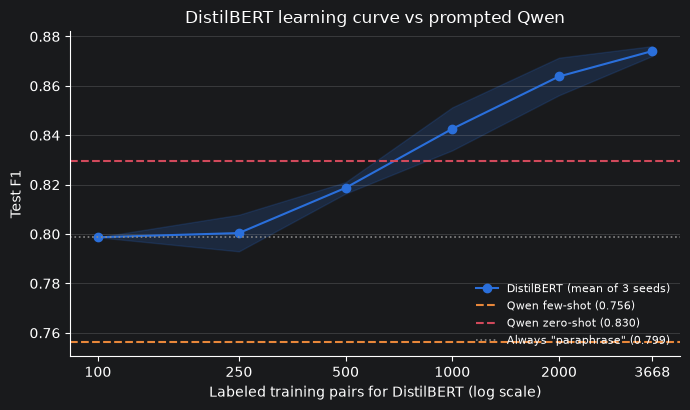

In [10]:
# ━━━ CELL 10: SUMMARY AND LEARNING CURVE WITH QWEN ━━━
runs = pd.read_csv(RUNS_CSV)
summary = (runs.groupby("mode")
               .agg(runs=("seed", "count"),
                    val_f1=("val_f1", "mean"), test_f1=("test_f1", "mean"), test_f1_sd=("test_f1", "std"),
                    test_acc=("test_accuracy", "mean"), said_yes=("test_said_yes", "mean"))
               .round(4).reset_index())
summary.to_csv(OUT_DIR / "summary.csv", index=False)
display(summary)

g3 = PROJECT_ROOT / "results" / "group3_distilbert" / "summary.csv"
always_yes = evaluate(test_df.label, np.ones(len(test_df), dtype=int))["f1"]
fig, ax = plt.subplots(figsize=(7, 4.2))
if g3.exists():
    d = pd.read_csv(g3)
    ax.plot(d.n_train, d.test_f1_mean, marker="o", color="#2a6fdb", label="DistilBERT (mean of 3 seeds)")
    ax.fill_between(d.n_train, d.test_f1_mean - d.test_f1_std.fillna(0), d.test_f1_mean + d.test_f1_std.fillna(0),
                    color="#2a6fdb", alpha=0.18)
    ax.set_xscale("log"); ax.set_xticks(list(d.n_train)); ax.set_xticklabels([str(v) for v in d.n_train])
    ax.minorticks_off()
colors = {"zero_shot": "#d1495b", "few_shot": "#e8873a"}
for r in summary.itertuples():
    ax.axhline(r.test_f1, color=colors.get(r.mode, "k"), ls="--", lw=1.5,
               label=f"Qwen {r.mode.replace('_', '-')} ({r.test_f1:.3f})")
ax.axhline(always_yes, color="#888888", ls=":", lw=1.2, label=f'Always "paraphrase" ({always_yes:.3f})')
ax.set_xlabel("Labeled training pairs for DistilBERT (log scale)")
ax.set_ylabel("Test F1")
ax.set_title("DistilBERT learning curve vs prompted Qwen")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "learning_curve_with_qwen.png", dpi=150)
plt.show()

## 11. Save results to GitHub

**Locally (PyCharm):** Git → Commit, tick `results/group4_qwen` and this notebook, then Commit and Push.

**In Colab:** run the cell below. It needs a classic GitHub token with the `repo` box ticked, saved in Colab Secrets as `GITHUB_TOKEN`.

In [ ]:
# ━━━ CELL 11: SAVE RESULTS TO GITHUB ━━━
GIT_NAME  = "Tim McGowan"
GIT_EMAIL = "tbm0929@gmail.com"

if IN_COLAB and not QUICK_TEST:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    push_url = REPO_URL.replace("https://", f"https://x-access-token:{token}@")

    def git(*cmd):
        r = subprocess.run(["git", "-C", str(PROJECT_ROOT), *cmd], capture_output=True, text=True)
        print((r.stdout + r.stderr).replace(token, "***").strip())
        return r.returncode

    git("config", "user.name", GIT_NAME)
    git("config", "user.email", GIT_EMAIL)
    git("add", "results/group4_qwen")
    git("commit", "-m", f"Group 4: Qwen results ({len(runs)} runs)")
    git("pull", "--rebase", push_url, "main")
    if git("push", push_url, "HEAD:main") == 0:
        print("Pushed to GitHub.")
else:
    print("Local run or quick test: commit from PyCharm instead (see the notes above).")